# [핸즈온 머신러닝] Chapter 2 – 머신러닝 프로젝트 처음부터 끝까지 (End-to-End Machine Learning Project)

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/jsmak/handson-mlp-study/blob/main/ch02/02_end_to_end_machine_learning_project_kr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>
<br clear="left"/>

> **📚 출처 및 라이선스**
>
> - **원본 노트북**: [rickiepark/handson-mlp](https://github.com/rickiepark/handson-mlp) – [`02_end_to_end_machine_learning_project.ipynb`](https://github.com/rickiepark/handson-mlp/blob/main/02_end_to_end_machine_learning_project.ipynb) (박해선 님, 『핸즈온 머신러닝 with 사이킷런, 파이토치』 한빛미디어, 2026 예제 코드)
> - **원저작**: [ageron/handson-mlp](https://github.com/ageron/handson-mlp) (Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn and PyTorch*, O'Reilly)
> - **라이선스**: 원본 코드는 [Apache License 2.0](https://github.com/rickiepark/handson-mlp/blob/main/LICENSE)을 따릅니다.
> - **변경 사항**: 개인 학습(인프런 챌린지 복습) 목적으로 원본 노트북을 바탕으로 한국어 설명·주석을 추가하고, 일부 시각화를 `folium`·`seaborn`으로 바꾸었으며, 셀 구성을 책의 절 번호에 맞춰 재정리했습니다. 책 본문은 포함하지 않습니다.

캘리포니아 인구 조사 데이터로 **구역별 중간 주택 가격(median_house_value)** 을 예측하는 프로젝트를 처음부터 끝까지 진행합니다.

| 단계 | 절 | 주요 코드 |
|---|---|---|
| 데이터 가져오기 | 2.3 | `load_housing_data()`, `train_test_split(stratify=...)` |
| 탐색과 시각화 | 2.4 | `folium`, `corr()`, `sns.pairplot()` |
| 데이터 준비 | 2.5 | `SimpleImputer`, `OneHotEncoder`, `StandardScaler`, `ColumnTransformer` |
| 모델 선택과 훈련 | 2.6 | `LinearRegression`, `DecisionTreeRegressor`, `RandomForestRegressor`, `cross_val_score` |
| 미세 튜닝 | 2.7 | `GridSearchCV`, `RandomizedSearchCV`, `bootstrap` |
| 론칭 | 2.8 | `joblib.dump()` / `joblib.load()` |

> 2.1, 2.2(문제 정의·성능 지표)와 2.3.1~2.3.4(코랩 사용법)는 코드가 없는 이론 절이라 블로그 정리에서 다룹니다.

## **2.3 데이터 가져오기**

캘리포니아 지역 주택의 여러 특성을 사용해 주택 중간 가격을 예측하는 예제입니다.

### **2.3.5 데이터 다운로드**

데이터(`housing.tgz`)를 내려받아 압축을 풀고 판다스 데이터프레임으로 읽어 옵니다.

In [1]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request
import sys
import numpy as np

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets", filter="data")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing_full = load_housing_data()
housing_full.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### **2.3.6 데이터 구조 훑어보기**

`info()`: 전체 샘플 수(20,640), 열별 데이터 타입, 결측치가 아닌 값의 개수를 확인합니다. → `total_bedrooms`에 결측치 207개

In [2]:
housing_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


범주형 특성 `ocean_proximity`의 카테고리별 구역 수를 확인합니다.

In [3]:
housing_full["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

`describe()`: 수치형 특성의 개수·평균·표준편차·최솟값·사분위수·최댓값을 보여 줍니다.

In [4]:
housing_full.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


수치형 특성마다 히스토그램을 그려 봅니다.

- 중간 소득은 달러 단위가 아닙니다(3 ≈ 3만 달러).
- 중간 주택 연식과 중간 주택 가격은 최댓값이 잘려 있습니다.
- 특성마다 스케일이 크게 다르고, 오른쪽 꼬리가 긴 분포가 많습니다.

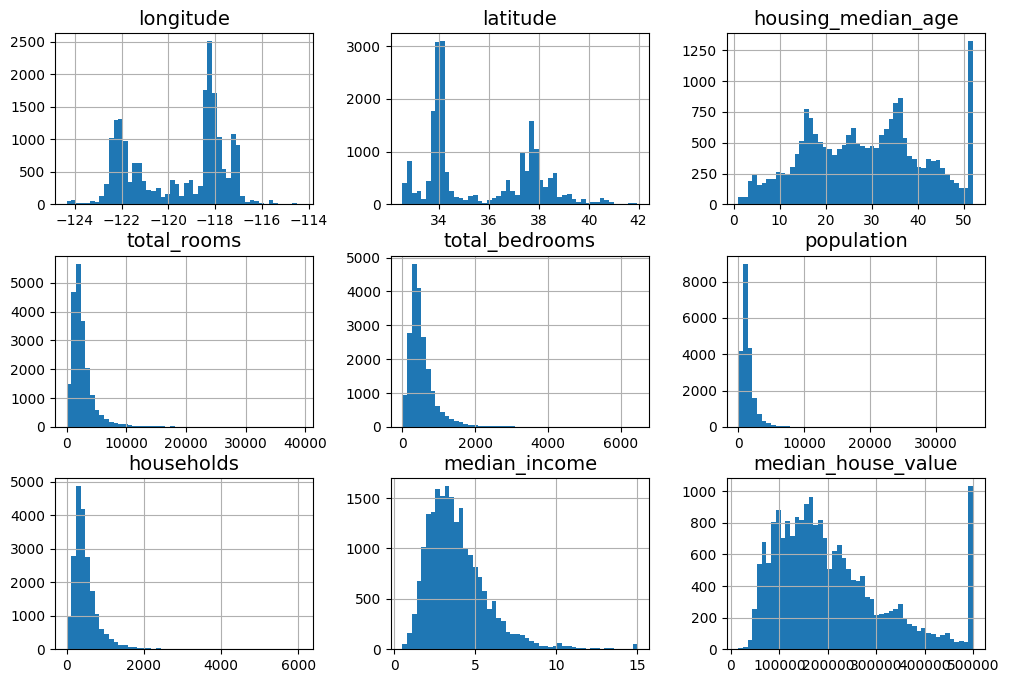

In [5]:
import matplotlib.pyplot as plt

# 추가 코드 – 다음 다섯 라인은 기본 폰트 크기를 지정합니다
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

housing_full.hist(bins=50, figsize=(12, 8))

plt.show()

### **2.3.7 테스트 세트 만들기**

가장 간단한 무작위 분할입니다. `random_state`를 고정해 실행할 때마다 같은 테스트 세트를 얻습니다.

In [6]:
from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(housing_full, test_size=0.2, random_state=42)
train_set.shape, test_set.shape

((16512, 10), (4128, 10))

**계층적 샘플링(stratified sampling)** 을 위해 중간 소득을 5개 소득 카테고리로 나눕니다.

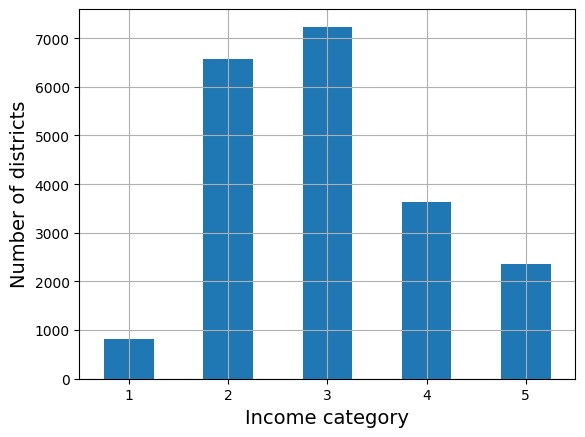

In [7]:
housing_full["income_cat"] = pd.cut(housing_full["median_income"],
                                    bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                                    labels=[1, 2, 3, 4, 5])
cat_counts = housing_full["income_cat"].value_counts().sort_index()
cat_counts.plot.bar(rot=0, grid=True)
plt.xlabel("Income category")
plt.ylabel("Number of districts")
plt.show()

`stratify` 매개변수로 소득 카테고리 비율을 유지하며 분할합니다.

In [8]:
strat_train_set, strat_test_set = train_test_split(housing_full, test_size=0.2, stratify=housing_full["income_cat"], random_state=42)
strat_train_set.shape, strat_test_set.shape

((16512, 11), (4128, 11))

In [9]:
strat_test_set["income_cat"].value_counts() / len(strat_test_set)

income_cat
3    0.350533
2    0.318798
4    0.176357
5    0.114341
1    0.039971
Name: count, dtype: float64

전체 데이터 / 계층 샘플링 / 무작위 샘플링의 소득 카테고리 비율을 비교합니다. → 계층 샘플링의 오차가 훨씬 작습니다.

In [10]:
def income_cat_proportions(data):
    return data["income_cat"].value_counts() / len(data)

train_set, test_set = train_test_split(housing_full, test_size=0.2,  random_state=42)

compare_props = pd.DataFrame({ "Overall %": income_cat_proportions(housing_full), 
                               "Stratified %": income_cat_proportions(strat_test_set), 
                               "Random %": income_cat_proportions(test_set),}).sort_index()
compare_props.index.name = "Income Category"
compare_props["Strat. Error %"] = (compare_props["Stratified %"] /  compare_props["Overall %"] - 1)
compare_props["Rand. Error %"] = (compare_props["Random %"] /  compare_props["Overall %"] - 1)
(compare_props * 100).round(2)

,Overall %,Stratified %,Random %,Strat. Error %,Rand. Error %
Income Category,,,,,
1,3.98,4.00,4.24,0.36,6.45
2,31.88,31.88,30.74,-0.02,-3.59
3,35.06,35.05,34.52,-0.01,-1.53
4,17.63,17.64,18.41,0.03,4.42
5,11.44,11.43,12.09,-0.08,5.63


`income_cat`은 분할에만 사용했으므로 삭제합니다.

In [11]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

## **2.4 데이터 이해를 위한 탐색과 시각화**

훈련 세트를 복사해서 탐색합니다 (테스트 세트는 보지 않습니다).

In [12]:
housing = strat_train_set.copy()

### **2.4.1 지리적 데이터 시각화하기**

책의 산점도 대신 `folium`으로 실제 지도 위에 표시합니다. (원 크기 = 인구, 색 = 중간 주택 가격)

> ⚠ 지도 출력은 용량(약 11MB)이 커서 저장소에서는 비워 두었습니다. 코랩에서 실행하면 지도를 볼 수 있습니다.
> → 해안가와 인구 밀집 지역의 주택 가격이 높습니다.

In [ ]:
# !pip install folium   # 설치되어 있지 않다면 주석을 풀고 실행
import folium
import branca.colormap as cm

m = folium.Map(location=[housing["latitude"].mean(), housing["longitude"].mean()], zoom_start=6)
colormap = cm.LinearColormap(colors=['blue', 'cyan', 'yellow', 'red'], vmin=housing["median_house_value"].min(), vmax=housing["median_house_value"].max())
colormap.caption = 'Median House Value'

# 구역마다 원 하나: 크기 = 인구, 색 = 중간 주택 가격
for _, row in housing.iterrows():
    folium.CircleMarker(location=[row["latitude"], row["longitude"]], radius=row["population"] / 500, color=colormap(row["median_house_value"]), fill=True, stroke=False).add_to(m)
m.add_child(colormap)
m

### **2.4.2 상관관계 조사하기**

모든 수치 특성 사이의 **표준 상관계수(피어슨 상관계수)** 를 계산하고, 중간 주택 가격과의 상관관계를 정렬합니다.

In [14]:
corr_matrix = housing.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
longitude            -0.050859
latitude             -0.139584
Name: median_house_value, dtype: float64

책의 `scatter_matrix` 대신 `seaborn.pairplot`으로 상관관계가 높아 보이는 특성 몇 개만 그립니다.

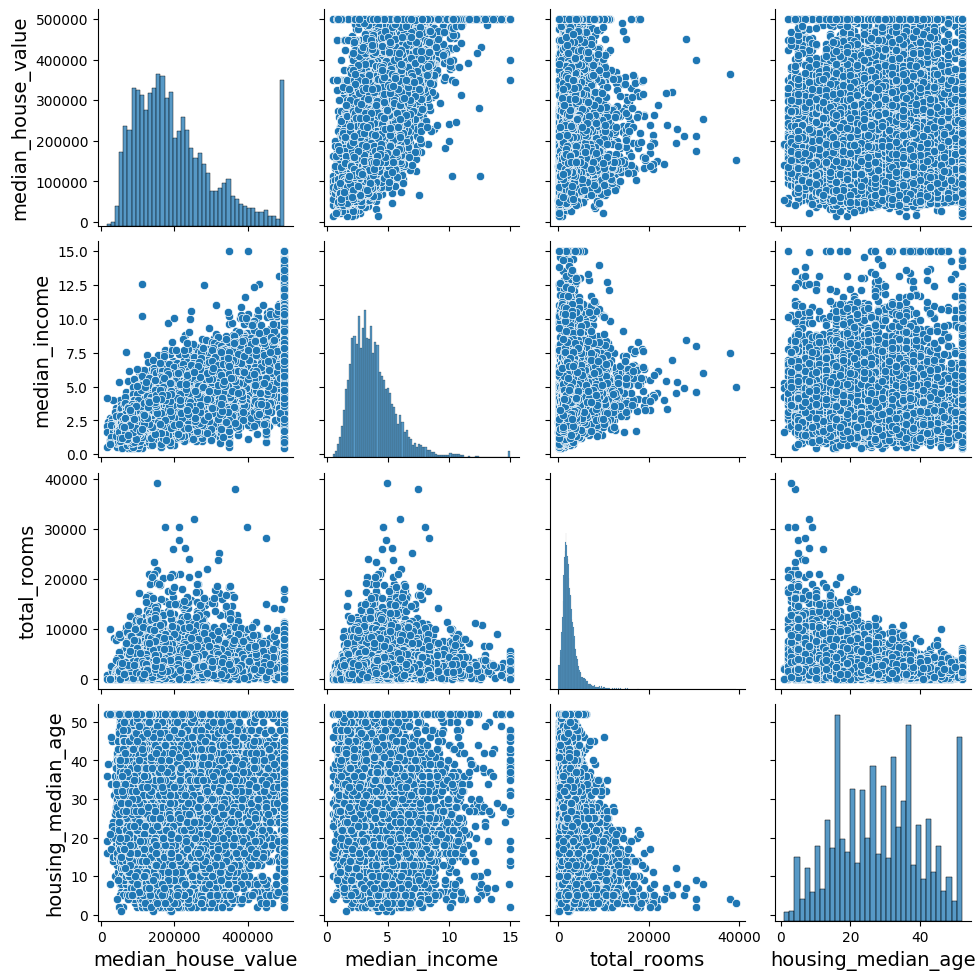

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
attributes = ["median_house_value", "median_income", "total_rooms", "housing_median_age"]
sns.pairplot(housing[attributes])
plt.show()

가장 유망한 중간 소득 vs 중간 주택 가격 산점도입니다. → 50만 달러(상한), 45만·35만·28만 달러 부근의 수평선이 보입니다.

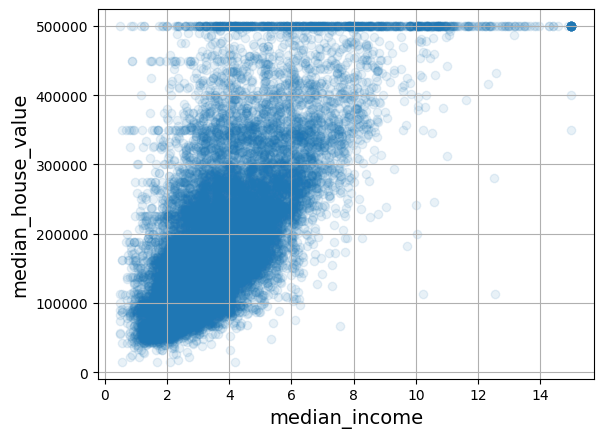

In [16]:
import matplotlib.pyplot as plt
plt.scatter(housing["median_income"], housing["median_house_value"], alpha=0.1)
plt.grid(True)
plt.xlabel("median_income")
plt.ylabel("median_house_value")
plt.show()

### **2.4.3 특성 조합으로 실험하기**

가구당 방 개수, 방 대비 침실 비율, 가구당 인원 특성을 만들어 상관관계를 다시 확인합니다. → `bedrooms_ratio`가 -0.26으로 더 유용합니다.

In [17]:
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_house"] = housing["population"] / housing["households"]
corr_matrix = housing.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
rooms_per_house       0.143663
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
people_per_house     -0.038224
longitude            -0.050859
latitude             -0.139584
bedrooms_ratio       -0.256397
Name: median_house_value, dtype: float64

## **2.5 머신러닝 알고리즘을 위한 데이터 준비**

원본 훈련 세트로 복원하고 타깃을 분리합니다.  
`strat_train_set.drop()`은 지정한 열을 제외한 `strat_train_set`의 복사본을 만듭니다.  
`inplace=True`로 지정하지 않은 한 `strat_train_set` 자체를 수정하지 않습니다.

In [18]:
housing = strat_train_set.drop("median_house_value", axis=1)
housing_labels = strat_train_set["median_house_value"].copy()

Note: 위 셀은 주택 데이터프레임을 재설정하고 방금 전 추가한 사용자 정의 특성을 삭제합니다.   
자동화된 '변환 파이프라인'을 구축해 이런 단계를 한 번에 처리할 예정이기 때문입니다.

### **2.5.1 데이터 정제**

책에서 소개한 결측치 값을 처리하는 세 개의 방법은 다음과 같습니다:

```python
housing.dropna(subset=["total_bedrooms"], inplace=True)    # 옵션 1  
housing.drop("total_bedrooms", axis=1, inplace=True)       # 옵션 2  
median = housing["total_bedrooms"].median()                # 옵션 3
housing["total_bedrooms"] = housing["total_bedrooms"].fillna(median)
```

결측치를 각 특성의 **중간값(median)** 으로 채우는 `SimpleImputer`를 만듭니다.

In [19]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")

`"median"` 전략을 사용하기 위해 수치 특성만 있는 데이터 복사본을 생성합니다(`ocean_proximity` 같은 텍스트 특성은 제외됩니다)

In [20]:
housing_num = housing.select_dtypes(include=[np.number])

훈련 세트로 각 특성의 중간값을 학습합니다 (결과는 `statistics_`에 저장).

In [21]:
imputer.fit(housing_num)

,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False


각 특성의 중간 값을 수동으로 계산한 것과 같은지 확인

In [22]:
print(imputer.statistics_)
print(housing_num.median().values)

[-118.51     34.26     29.     2125.      434.     1167.      408.
    3.5385]
[-118.51     34.26     29.     2125.      434.     1167.      408.
    3.5385]


훈련 세트에서, 결측치를 median으로 변경합니다.

학습한 중간값으로 결측치를 채웁니다. 결과는 넘파이 배열입니다.

In [23]:
X = imputer.transform(housing_num)

넘파이 배열을 열 이름·인덱스가 있는 데이터프레임으로 복원하고 결측치가 사라졌는지 확인합니다.

In [24]:
housing_tr = pd.DataFrame(X, columns=housing_num.columns, index=housing_num.index)
print(housing_num['total_bedrooms'].isna().sum())
print(housing_tr['total_bedrooms'].isna().sum())

168
0


### **2.5.2 텍스트와 범주형 특성 다루기**

이제 범주형 입력 특성인 `ocean_proximity`을 전처리합니다:

In [25]:
housing_cat = housing[["ocean_proximity"]]
housing_cat.head(8)

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN
1286,INLAND
18078,<1H OCEAN
4396,NEAR BAY


`OrdinalEncoder`: 카테고리를 0, 1, 2 … 정수로 바꿉니다. 순서가 없는 카테고리에는 부적절할 수 있습니다.

In [26]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()
housing_cat_encoded = ordinal_encoder.fit_transform(housing_cat)
housing_cat_encoded[:8]

array([[3.],
       [0.],
       [1.],
       [1.],
       [4.],
       [1.],
       [0.],
       [3.]])

In [27]:
ordinal_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

`OneHotEncoder`: 카테고리마다 이진 특성을 만들어 해당 카테고리만 1로 표시합니다.

In [28]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder()
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
housing_cat_1hot

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16512 stored elements and shape (16512, 5)>

`OneHotEncoder`는 기본적으로 희소 행렬을 반환합니다. 필요하면 `toarray()` 메서드를 사용해 밀집 배열로 변환할 수 있습니다:

In [29]:
housing_cat_1hot.toarray()

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

또는 `OneHotEncoder`를 만들 때 `sparse_output=False`로 지정할 수 있습니다.  

In [30]:
cat_encoder = OneHotEncoder(sparse_output=False)
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
housing_cat_1hot

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

In [31]:
cat_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

`pd.get_dummies()`는 입력에 있는 카테고리만 열로 만들지만, `OneHotEncoder`는 훈련 때 본 카테고리 구성을 유지합니다.

In [32]:
df_test = pd.DataFrame({"ocean_proximity": ["INLAND", "NEAR BAY"]})
print(pd.get_dummies(df_test))
cat_encoder.transform(df_test)

   ocean_proximity_INLAND  ocean_proximity_NEAR BAY
0                    True                     False
1                   False                      True


array([[0., 1., 0., 0., 0.],
       [0., 0., 0., 1., 0.]])

훈련 때 보지 못한 카테고리(`<2H OCEAN`)가 들어오면 `OneHotEncoder`는 기본적으로 오류를 냅니다. `handle_unknown="ignore"`로 지정하면 모두 0으로 표시합니다.

In [33]:
df_test_unknown = pd.DataFrame({"ocean_proximity": ["<2H OCEAN", "ISLAND"]})
print(pd.get_dummies(df_test_unknown))
# cat_encoder.transform(df_test_unknown) # 오류 발생
cat_encoder.handle_unknown = "ignore"
cat_encoder.transform(df_test_unknown) # unknown을 0으로 표시

   ocean_proximity_<2H OCEAN  ocean_proximity_ISLAND
0                       True                   False
1                      False                    True


array([[0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0.]])

`feature_names_in_`과 `get_feature_names_out()`으로 출력을 데이터프레임으로 만들 수 있습니다.

In [34]:
print(cat_encoder.feature_names_in_)
print(cat_encoder.get_feature_names_out())
df_output = pd.DataFrame(cat_encoder.transform(df_test_unknown), columns=cat_encoder.get_feature_names_out(), index=df_test_unknown.index)
df_output

['ocean_proximity']
['ocean_proximity_<1H OCEAN' 'ocean_proximity_INLAND'
 'ocean_proximity_ISLAND' 'ocean_proximity_NEAR BAY'
 'ocean_proximity_NEAR OCEAN']


,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0


### **2.5.3 특성 스케일과 변환**

**min-max 스케일링**: `feature_range=(-1, 1)`로 -1~1 범위로 맞춥니다.

In [35]:
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler(feature_range=(-1, 1))
housing_num_min_max_scaled = min_max_scaler.fit_transform(housing_num)
housing_num_min_max_scaled.round(3)

array([[-0.609,  0.117,  1.   , ..., -0.807, -0.614, -0.779],
       [ 0.211, -0.662,  0.529, ..., -0.919, -0.867, -0.229],
       [-0.519,  0.236,  0.255, ..., -0.931, -0.925, -0.733],
       ...,
       [ 0.479, -0.991, -0.529, ..., -0.655, -0.717, -0.509],
       [ 0.207, -0.679,  0.412, ..., -0.789, -0.688, -0.497],
       [-0.606,  0.087,  0.686, ..., -0.917, -0.921, -0.616]])

**표준화(standardization)**: 평균을 빼고 표준편차로 나눕니다. 이상치의 영향을 덜 받습니다.

In [36]:
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()
housing_num_std_scaled = std_scaler.fit_transform(housing_num)
housing_num_std_scaled.round(3)

array([[-1.423,  1.014,  1.861, ...,  0.137,  1.395, -0.936],
       [ 0.596, -0.702,  0.908, ..., -0.694, -0.373,  1.172],
       [-1.203,  1.276,  0.351, ..., -0.789, -0.776, -0.76 ],
       ...,
       [ 1.256, -1.429, -1.238, ...,  1.268,  0.679,  0.101],
       [ 0.586, -0.74 ,  0.669, ...,  0.274,  0.883,  0.145],
       [-1.418,  0.948,  1.225, ..., -0.679, -0.752, -0.31 ]])

꼬리가 두꺼운 `population`을 로그로 바꾸면 분포가 대칭에 가까워집니다.

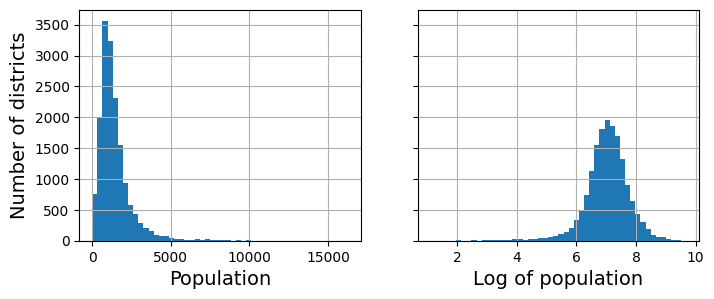

In [37]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
housing["population"].hist(ax=axs[0], bins=50)
housing["population"].apply(np.log).hist(ax=axs[1], bins=50)
axs[0].set_xlabel("Population")
axs[1].set_xlabel("Log of population")
axs[0].set_ylabel("Number of districts")

plt.show()

**버킷타이징(bucketizing)**: 꼬리가 두꺼운 특성을 처리하는 또 다른 방법입니다.
각 값을 백분위수로 바꾸면 거의 동일한 크기의 버킷으로 나뉘어 균등 분포에 가까운 특성이 되므로, 추가로 스케일링할 필요가 없습니다.

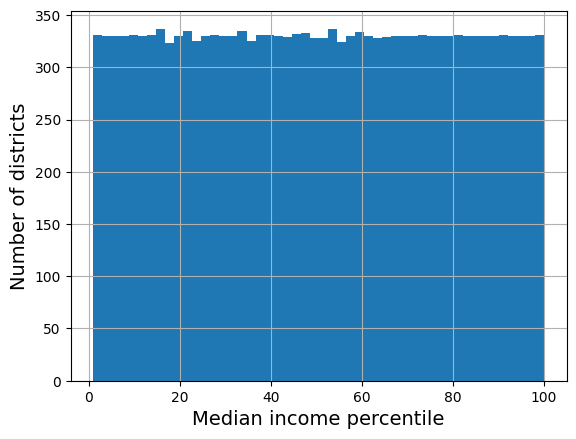

In [38]:
percentiles = [np.percentile(housing["median_income"], p) for p in range(1, 100)]
flattened_median_income = pd.cut(housing["median_income"], bins=[-np.inf] + percentiles + [np.inf], labels=range(1, 100 + 1))
flattened_median_income.hist(bins=50)
plt.xlabel("Median income percentile")
plt.ylabel("Number of districts")
plt.show()
# Note: 1 백분위수 아래의 소득은 1로 레이블되고 99 백분위수 이상의 값은 100으로 레이블됩니다.
# 이 때문에 아래 분포의 범위가 1에서부터 100까지입니다

**가우스 RBF**로 주택 연식과 35년 사이의 유사도를 계산합니다: $\exp(-\gamma(x-35)^2)$

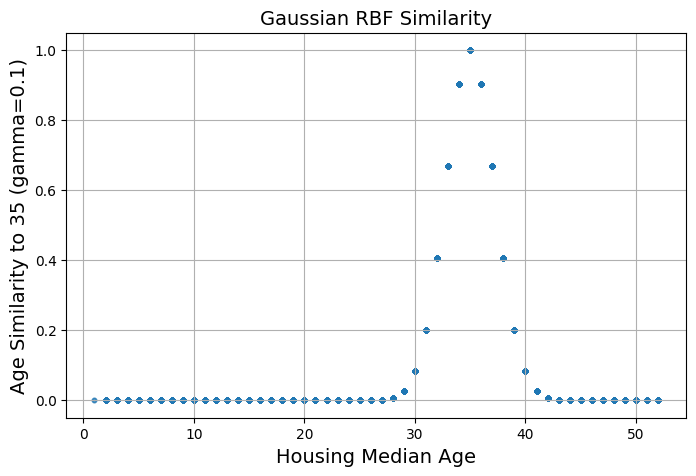

In [39]:
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import rbf_kernel

age_simil_35 = rbf_kernel(housing[["housing_median_age"]], [[35]], gamma=0.1)
plt.figure(figsize=(8, 5))
plt.scatter(housing["housing_median_age"], age_simil_35, alpha=0.3, s=10)
plt.xlabel("Housing Median Age")
plt.ylabel("Age Similarity to 35 (gamma=0.1)")
plt.title("Gaussian RBF Similarity")
plt.grid(True)
plt.show()

`gamma`가 작을수록 유사도가 천천히 감소합니다.

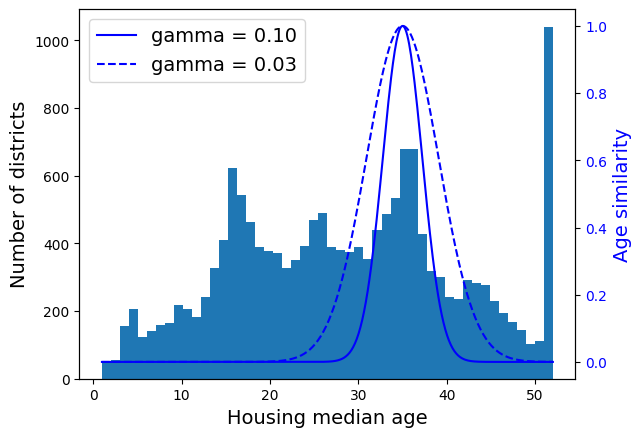

In [40]:
ages = np.linspace(housing["housing_median_age"].min(), housing["housing_median_age"].max(), 500).reshape(-1, 1)
gamma1 = 0.1
gamma2 = 0.03
rbf1 = rbf_kernel(ages, [[35]], gamma=gamma1)
rbf2 = rbf_kernel(ages, [[35]], gamma=gamma2)

fig, ax1 = plt.subplots()

ax1.set_xlabel("Housing median age")
ax1.set_ylabel("Number of districts")
ax1.hist(housing["housing_median_age"], bins=50)

ax2 = ax1.twinx()  # x축을 공유 하는 쌍둥이 축을 만듭니다
color = "blue"
ax2.plot(ages, rbf1, color=color, label="gamma = 0.10")
ax2.plot(ages, rbf2, color=color, label="gamma = 0.03", linestyle="--")
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylabel("Age similarity", color=color)
plt.legend(loc="upper left")

plt.show()

타깃(레이블)을 스케일링해서 훈련한 뒤 `inverse_transform()`으로 원래 스케일로 되돌리는 방법입니다.

In [41]:
from sklearn.linear_model import LinearRegression

target_scaler = StandardScaler()
scaled_labels = target_scaler.fit_transform(housing_labels.to_frame())

model = LinearRegression()
model.fit(housing[["median_income"]], scaled_labels)
some_new_data = housing[["median_income"]].iloc[:5]  # 새로운 데이터라고 가정합니다

scaled_predictions = model.predict(some_new_data)
predictions = target_scaler.inverse_transform(scaled_predictions)
predictions

array([[131997.15275877],
       [299359.35844434],
       [146023.37185694],
       [138840.33653057],
       [192016.61557639]])

`TransformedTargetRegressor`를 쓰면 타깃 스케일링과 역변환을 자동으로 처리해 줍니다.

In [42]:
from sklearn.compose import TransformedTargetRegressor

model = TransformedTargetRegressor(LinearRegression(),
                                   transformer=StandardScaler())
model.fit(housing[["median_income"]], housing_labels)
predictions = model.predict(some_new_data)
predictions

array([131997.15275877, 299359.35844434, 146023.37185694, 138840.33653057,
       192016.61557639])

### **2.5.4 사용자 정의 변환기**

로그 변환기를 만들어 population 특성에 적용해 보겠습니다.

In [43]:
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log, inverse_func=np.exp)
log_pop = log_transformer.transform(housing[["population"]])
log_pop.head()

,population
13096,7.362645
14973,6.501290
3785,6.331502
14689,7.520235
20507,7.555905


하이퍼파라미터를 `kw_args`로 넘겨 RBF 유사도 변환기를 만듭니다.

In [44]:
rbf_transformer = FunctionTransformer(rbf_kernel, kw_args=dict(Y=[[35.]], gamma=0.1))
age_simil_35 = rbf_transformer.transform(housing[["housing_median_age"]])
pd.DataFrame({ "original_age": housing["housing_median_age"], "age_simil_35": age_simil_35.flatten()}).round(3)

,original_age,age_simil_35
13096,52.0,0.000
14973,40.0,0.082
3785,33.0,0.670
14689,17.0,0.000
20507,36.0,0.905
...,...,...
14207,41.0,0.027
13105,23.0,0.000
19301,13.0,0.000
19121,37.0,0.670


특성 2개(위도, 경도)를 넣으면 샌프란시스코와의 2D 거리 기반 유사도를 계산합니다.

In [45]:
sf_coords = 37.7749, -122.41
sf_transformer = FunctionTransformer(rbf_kernel, kw_args=dict(Y=[sf_coords], gamma=0.1))
sf_simil = sf_transformer.transform(housing[["latitude", "longitude"]])
sf_simil.round(5)

array([[0.99993],
       [0.05258],
       [0.94864],
       ...,
       [0.00389],
       [0.05039],
       [0.99868]])

두 특성의 비율을 계산하는 변환기입니다.

In [46]:
ratio_transformer = FunctionTransformer(lambda X: X[:, [0]] / X[:, [1]])
ratio_transformer.transform(np.array([[1., 2.], [3., 4.]]))

array([[0.5 ],
       [0.75]])

훈련이 필요한 변환기는 `BaseEstimator`, `TransformerMixin`을 상속해 클래스로 만듭니다. `StandardScaler`를 흉내 낸 클래스로 결과를 비교합니다.

In [47]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.utils.validation import check_array, check_is_fitted

class StandardScalerClone(BaseEstimator, TransformerMixin):
    def __init__(self, with_mean=True):  # *args나 **kwargs를 사용하지 않습니다!
        self.with_mean = with_mean

    def fit(self, X, y=None):  # 사용하지 않더라도 y를 넣어 주어야 합니다
        X = check_array(X)  # X가 부동소수점 배열인지 확인합니다
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.scale_[self.scale_ == 0] = 1  # 상수 특성의 경우 0 나눗셈을 피합니다
        self.n_features_in_ = X.shape[1]  # 모든 추정기는 fit()에서 이를 저장합니다
        return self  # 항상 self를 반환합니다!

    def transform(self, X):
        check_is_fitted(self)  # 학습된 속성(끝에 _가 붙은 속성)이 있는지 확인합니다
        X = check_array(X)
        assert self.n_features_in_ == X.shape[1]
        if self.with_mean:
            X = X - self.mean_
        return X / self.scale_


# 1. 간단한 테스트 데이터 생성 (3행 2열)
X_demo = np.array([
    [1.0, 10.0],
    [3.0, 20.0],
    [5.0, 30.0]
])

# 2. 직접 만든 StandardScalerClone 적용
# TransformerMixin을 상속받았으므로 fit_transform()을 바로 사용할 수 있습니다.
clone_scaler = StandardScalerClone(with_mean=True)
X_scaled_clone = clone_scaler.fit_transform(X_demo)

# 3. 사이킷런의 실제 StandardScaler 적용
real_scaler = StandardScaler(with_mean=True)
X_scaled_real = real_scaler.fit_transform(X_demo)

# 4. 결과 출력 및 비교
print("\n=== StandardScalerClone 변환 결과 ===")
print(X_scaled_clone)

print("\n=== 사이킷런 StandardScaler 변환 결과 ===")
print(X_scaled_real)


=== StandardScalerClone 변환 결과 ===
[[-1.22474487 -1.22474487]
 [ 0.          0.        ]
 [ 1.22474487  1.22474487]]

=== 사이킷런 StandardScaler 변환 결과 ===
[[-1.22474487 -1.22474487]
 [ 0.          0.        ]
 [ 1.22474487  1.22474487]]


`fit()`에서 k-평균으로 클러스터 중심을 찾고, `transform()`에서 각 구역과 클러스터 중심 사이의 RBF 유사도를 계산하는 변환기입니다.

In [48]:
from sklearn.cluster import KMeans

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y=None, sample_weight=None):
        self.kmeans_ = KMeans(self.n_clusters, random_state=self.random_state)
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self  # 항상 self를 반환합니다!

    def transform(self, X):
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma)

    def get_feature_names_out(self, names=None):
        return [f"클러스터 {i} 유사도" for i in range(self.n_clusters)]

cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
similarities = cluster_simil.fit_transform(housing[["latitude", "longitude"]])        

similarities[:3].round(2)

array([[0.46, 0.  , 0.08, 0.  , 0.  , 0.  , 0.  , 0.98, 0.  , 0.  ],
       [0.  , 0.96, 0.  , 0.03, 0.04, 0.  , 0.  , 0.  , 0.11, 0.35],
       [0.34, 0.  , 0.45, 0.  , 0.  , 0.  , 0.01, 0.73, 0.  , 0.  ]])

클러스터 중심(X)과 각 구역의 최대 클러스터 유사도를 지도처럼 그립니다. → 대부분의 클러스터가 인구 밀집 지역에 있습니다.

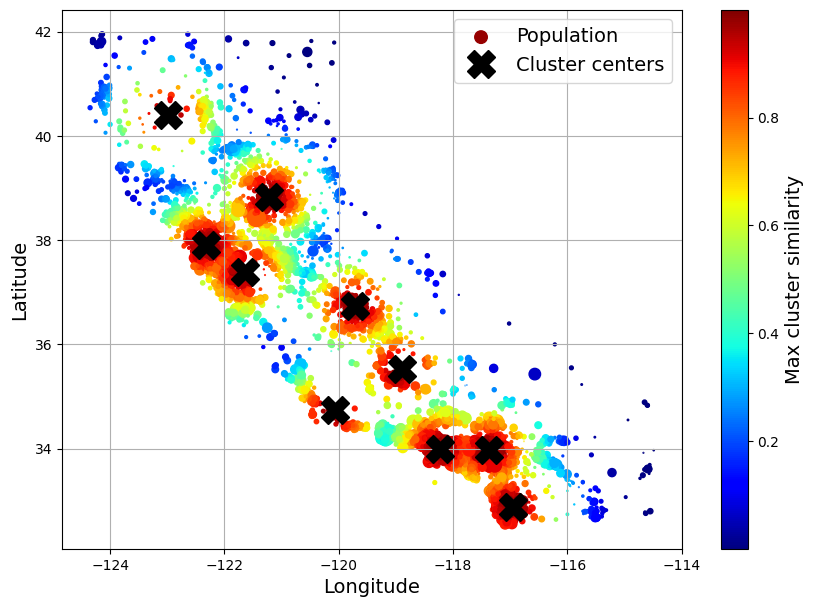

In [49]:
housing_renamed = housing.rename(columns={"latitude": "Latitude", "longitude": "Longitude", "population": "Population", "median_house_value": "Median house value (ᴜsᴅ)"})
housing_renamed["Max cluster similarity"] = similarities.max(axis=1)
housing_renamed.plot(kind="scatter", x="Longitude", y="Latitude", grid=True, s=housing_renamed["Population"] / 100, label="Population", c="Max cluster similarity", cmap="jet", colorbar=True, legend=True, sharex=False, figsize=(10, 7))
plt.plot(cluster_simil.kmeans_.cluster_centers_[:, 1], cluster_simil.kmeans_.cluster_centers_[:, 0], linestyle="", color="black", marker="X", markersize=20, label="Cluster centers")
plt.legend(loc="upper right")
plt.show()

### **2.5.5 변환 파이프라인**

수치 특성의 결측치를 처리하고 스케일을 조정하는 간단한 파이프라인입니다.

In [50]:
from sklearn.pipeline import Pipeline
num_pipeline = Pipeline([("impute", SimpleImputer(strategy="median")), ("standardize", StandardScaler())])

주피터 노트북에서 `set_config(display="diagram")`을 실행하면 파이프라인이 인터랙티브한 다이어그램으로 표시됩니다.
파이프라인 구조를 확인할 때 유용합니다.

In [51]:
from sklearn import set_config
set_config(display='diagram')
num_pipeline

,steps,"[('impute', ...), ('standardize', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


`make_pipeline()`은 단계 이름을 클래스 이름의 소문자로 자동 지정합니다.

In [52]:
from sklearn.pipeline import make_pipeline

num_pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
num_pipeline

,steps,"[('simpleimputer', ...), ('standardscaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [53]:
housing_num_prepared = num_pipeline.fit_transform(housing_num)
housing_num_prepared[:2].round(2)

array([[-1.42,  1.01,  1.86,  0.31,  1.37,  0.14,  1.39, -0.94],
       [ 0.6 , -0.7 ,  0.91, -0.31, -0.44, -0.69, -0.37,  1.17]])

In [54]:
df_housing_num_prepared = pd.DataFrame(housing_num_prepared, columns=num_pipeline.get_feature_names_out(), index=housing_num.index)
df_housing_num_prepared.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942
3785,-1.203098,1.276119,0.351428,-0.712240,-0.760709,-0.788768,-0.775727,-0.759789
14689,1.231216,-0.884924,-0.919891,0.702262,0.742306,0.383175,0.731375,-0.850281
20507,0.711362,-0.875549,0.589800,0.790125,1.595753,0.444376,1.755263,-0.180365


`ColumnTransformer`로 수치형에는 `num_pipeline`, 범주형에는 `cat_pipeline`을 적용합니다.

In [55]:
from sklearn.compose import ColumnTransformer

num_attribs = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income"]
cat_attribs = ["ocean_proximity"]

cat_pipeline = make_pipeline(SimpleImputer(strategy="most_frequent"),  OneHotEncoder(handle_unknown="ignore"))
preprocessing = ColumnTransformer([("num", num_pipeline, num_attribs), ("cat", cat_pipeline, cat_attribs)])
housing_prepared = preprocessing.fit_transform(housing)
pd.DataFrame(housing_prepared, columns=preprocessing.get_feature_names_out(), index=housing.index).head(2)

,num__longitude,num__latitude,num__housing_median_age,num__total_rooms,num__total_bedrooms,num__population,num__households,num__median_income,cat__ocean_proximity_<1H OCEAN,cat__ocean_proximity_INLAND,cat__ocean_proximity_ISLAND,cat__ocean_proximity_NEAR BAY,cat__ocean_proximity_NEAR OCEAN
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491,0.0,0.0,0.0,1.0,0.0
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942,1.0,0.0,0.0,0.0,0.0


`make_column_selector`로 열 이름 대신 데이터 타입으로 열을 선택할 수 있습니다. (변환기 이름은 `pipeline-1`, `pipeline-2`로 자동 지정)

In [56]:
from sklearn.compose import make_column_selector, make_column_transformer
preprocessing = make_column_transformer((num_pipeline, make_column_selector(dtype_include=np.number)), (cat_pipeline, make_column_selector(dtype_include=object)))
housing_prepared = preprocessing.fit_transform(housing)
pd.DataFrame(housing_prepared, columns=preprocessing.get_feature_names_out(), index=housing.index).head(2)

,pipeline-1__longitude,pipeline-1__latitude,pipeline-1__housing_median_age,pipeline-1__total_rooms,pipeline-1__total_bedrooms,pipeline-1__population,pipeline-1__households,pipeline-1__median_income,pipeline-2__ocean_proximity_<1H OCEAN,pipeline-2__ocean_proximity_INLAND,pipeline-2__ocean_proximity_ISLAND,pipeline-2__ocean_proximity_NEAR BAY,pipeline-2__ocean_proximity_NEAR OCEAN
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491,0.0,0.0,0.0,1.0,0.0
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942,1.0,0.0,0.0,0.0,0.0


지금까지 실험한 변환을 모두 담은 최종 전처리 파이프라인입니다.

- 비율 특성 3개, 로그 변환 5개, 클러스터 유사도 10개, 원-핫 5개, 나머지(`housing_median_age`) 1개 → **24개 특성**

In [57]:
def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]  # get_feature_names_out에 사용

def ratio_pipeline():
    return make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(column_ratio, feature_names_out=ratio_name), StandardScaler())

log_pipeline = make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log, feature_names_out="one-to-one"), StandardScaler())
cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
default_num_pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
preprocessing = ColumnTransformer([
        ("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]),
        ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]),
        ("people_per_house", ratio_pipeline(), ["population", "households"]),
        ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population", "households", "median_income"]),
        ("geo", cluster_simil, ["latitude", "longitude"]),
        ("cat", cat_pipeline, make_column_selector(dtype_include=object)),
    ], remainder=default_num_pipeline)  # 남은 특성: housing_median_age
housing_prepared = preprocessing.fit_transform(housing)
print(housing_prepared.shape)
pd.DataFrame(housing_prepared, columns=preprocessing.get_feature_names_out(), index=housing.index).head(2)

(16512, 24)


,bedrooms__ratio,rooms_per_house__ratio,people_per_house__ratio,log__total_bedrooms,log__total_rooms,log__population,log__households,log__median_income,geo__클러스터 0 유사도,geo__클러스터 1 유사도,...,geo__클러스터 6 유사도,geo__클러스터 7 유사도,geo__클러스터 8 유사도,geo__클러스터 9 유사도,cat__ocean_proximity_<1H OCEAN,cat__ocean_proximity_INLAND,cat__ocean_proximity_ISLAND,cat__ocean_proximity_NEAR BAY,cat__ocean_proximity_NEAR OCEAN,remainder__housing_median_age
13096,1.846624,-0.866027,-0.330204,1.324114,0.637892,0.456906,1.310369,-1.071522,4.581829e-01,1.241847e-14,...,8.489216e-04,9.770322e-01,2.382191e-08,3.819126e-18,0.0,0.0,0.0,1.0,0.0,1.861119
14973,-0.508121,0.024550,-0.253616,-0.252671,-0.063576,-0.711654,-0.142030,1.194712,6.511495e-10,9.579596e-01,...,5.614049e-27,1.260964e-13,1.103491e-01,3.547610e-01,1.0,0.0,0.0,0.0,0.0,0.907630


## **2.6 모델 선택과 훈련**

### **2.6.1 훈련 세트에서 훈련하고 평가하기**

선형 회귀를 훈련 세트에서 훈련·평가합니다. → RMSE 약 68,973달러로 **과소적합**

In [58]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error 

lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(housing, housing_labels)
housing_predictions = lin_reg.predict(housing)
print(housing_predictions[:5].round(-2))  # -2 = 십의 자리에서 반올림
print(housing_labels.iloc[:5].values)
print(root_mean_squared_error(housing_labels, housing_predictions))

[246000. 372700. 135700.  91400. 330900.]
[458300. 483800. 101700.  96100. 361800.]
68972.88910758478


결정 트리 회귀 → 훈련 세트 RMSE 0, 심한 **과대적합**이 의심됩니다.

In [59]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = make_pipeline(preprocessing, DecisionTreeRegressor(random_state=42))
tree_reg.fit(housing, housing_labels)
housing_predictions = tree_reg.predict(housing)
print(housing_predictions[:5].round(-2))  # -2 = 십의 자리에서 반올림
print(housing_labels.iloc[:5].values)
print(root_mean_squared_error(housing_labels, housing_predictions))

[458300. 483800. 101700.  96100. 361800.]
[458300. 483800. 101700.  96100. 361800.]
0.0


### **2.6.2 교차 검증으로 평가하기**

**k-폴드 교차 검증(k=10)** 으로 다시 평가합니다. 사이킷런은 점수가 클수록 좋다고 가정하므로 `neg_root_mean_squared_error`에 `-`를 붙입니다.

In [60]:
from sklearn.model_selection import cross_val_score
lin_rmses = -cross_val_score(lin_reg, housing, housing_labels,  scoring="neg_root_mean_squared_error", cv=10)
print(lin_rmses.mean())
print(lin_rmses)
tree_rmses = -cross_val_score(tree_reg, housing, housing_labels,  scoring="neg_root_mean_squared_error", cv=10)
print(tree_rmses.mean())
print(tree_rmses)

70003.40481808134
[69857.22858234 68416.6472971  65504.76575251 81037.86374148
 69063.09688723 68424.89361011 67952.06647592 71179.43136955
 68090.53867535 70507.51578923]


66573.73460009348
[64607.89604624 66409.0627187  66203.41031283 65863.76434319
 68086.79141027 66534.53308312 66923.49892937 68532.21066423
 66367.48227837 66208.69621463]


**경고:** 다음 셀은 실행하는데 몇 분이 걸릴 수 있습니다:

In [61]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = make_pipeline(preprocessing, RandomForestRegressor(random_state=42))
forest_rmses = -cross_val_score(forest_reg, housing, housing_labels, scoring="neg_root_mean_squared_error", cv=10)
print(forest_rmses.mean())
print(forest_rmses)

47038.09279895258
[46576.85817312 47238.61187815 45495.97664925 46488.27129295
 45911.17628527 47730.60806253 47561.15494003 49140.83221016
 47121.06435179 47116.37414628]


## **2.7 모델 미세 튜닝**

### **2.7.1 그리드 서치**

`GridSearchCV`로 전처리(`n_clusters`)와 모델(`max_features`) 하이퍼파라미터를 함께 탐색합니다.

- 조합: 3×3 + 2×3 = 15개, 3-폴드 → 총 45번 훈련
- `preprocessing__geo__n_clusters`: 이중 밑줄(`__`)로 파이프라인 → ColumnTransformer → `geo` 변환기를 찾아 들어갑니다.

In [62]:
from sklearn.model_selection import GridSearchCV

full_pipeline = Pipeline([("preprocessing", preprocessing), ("random_forest", RandomForestRegressor(random_state=42))])
param_grid = [
    {'preprocessing__geo__n_clusters': [5, 8, 10],
     'random_forest__max_features': [4, 6, 8]},
    {'preprocessing__geo__n_clusters': [10, 15],
     'random_forest__max_features': [6, 8, 10]},
]
grid_search = GridSearchCV(full_pipeline, param_grid, cv=3, scoring='neg_root_mean_squared_error')
grid_search.fit(housing, housing_labels)
print(str(full_pipeline.get_params().keys())[:1000] + "...")
print(grid_search.best_params_)
print(grid_search.best_estimator_)

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'preprocessing', 'random_forest', 'preprocessing__force_int_remainder_cols', 'preprocessing__n_jobs', 'preprocessing__remainder__memory', 'preprocessing__remainder__steps', 'preprocessing__remainder__transform_input', 'preprocessing__remainder__verbose', 'preprocessing__remainder__simpleimputer', 'preprocessing__remainder__standardscaler', 'preprocessing__remainder__simpleimputer__add_indicator', 'preprocessing__remainder__simpleimputer__copy', 'preprocessing__remainder__simpleimputer__fill_value', 'preprocessing__remainder__simpleimputer__keep_empty_features', 'preprocessing__remainder__simpleimputer__missing_values', 'preprocessing__remainder__simpleimputer__strategy', 'preprocessing__remainder__standardscaler__copy', 'preprocessing__remainder__standardscaler__with_mean', 'preprocessing__remainder__standardscaler__with_std', 'preprocessing__remainder', 'preprocessing__sparse_threshold', 'preprocessing__transformer_weights', 

그리드 탐색에서 테스트한 하이퍼파라미터 조합의 점수를 확인해 보죠:

In [63]:
cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)
cv_res = cv_res[["param_preprocessing__geo__n_clusters", "param_random_forest__max_features", "split0_test_score", "split1_test_score", "split2_test_score", "mean_test_score"]]
score_cols = ["split0", "split1", "split2", "mean_test_rmse"]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)
cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
12,15,6,42725,43708,44335,43590
13,15,8,43486,43820,44900,44069
6,10,4,43798,44036,44961,44265
9,10,6,43710,44163,44967,44280
7,10,6,43710,44163,44967,44280


### **2.7.2 랜덤 서치**

`RandomizedSearchCV`: 지정한 분포에서 무작위로 하이퍼파라미터를 뽑아 `n_iter`번만 평가합니다.

In [64]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distribs = {'preprocessing__geo__n_clusters': randint(low=3, high=50), 'random_forest__max_features': randint(low=2, high=20)}

rnd_search = RandomizedSearchCV(full_pipeline, param_distributions=param_distribs, n_iter=10, cv=3, scoring='neg_root_mean_squared_error', random_state=42)
rnd_search.fit(housing, housing_labels)
cv_res = pd.DataFrame(rnd_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)
cv_res = cv_res[["param_preprocessing__geo__n_clusters", "param_random_forest__max_features", "split0_test_score", "split1_test_score", "split2_test_score", "mean_test_score"]]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)
cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
1,45,9,41342,42242,43057,42214
8,32,7,41825,42275,43241,42447
0,41,16,42238,42938,43354,42843
5,42,4,41869,43362,43664,42965
2,23,8,42490,42928,43718,43046


In [65]:
# 참고: 실험적 기능이라 enable_halving_search_cv를 먼저 임포트해야 합니다 (여기서는 임포트만 해 둡니다)
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV

### **2.7.3 앙상블 기법**

최상의 모델 여러 개를 연결하면 단일 모델보다 성능이 좋아지는 경우가 많습니다. (7장에서 자세히 다룹니다. 이 절은 코드가 없습니다.)

### **2.7.4 최상의 모델과 오차 분석**

랜덤 포레스트가 알려 주는 **특성 중요도**를 내림차순으로 확인합니다.

In [66]:
final_model = rnd_search.best_estimator_  # 전처리 포함됨
feature_importances = final_model["random_forest"].feature_importances_
pd.Series(feature_importances, index=final_model["preprocessing"].get_feature_names_out()).sort_values(ascending=False)

log__median_income                 0.185997
cat__ocean_proximity_INLAND        0.073389
bedrooms__ratio                    0.065569
rooms_per_house__ratio             0.053649
people_per_house__ratio            0.045989
geo__클러스터 30 유사도                   0.041753
geo__클러스터 25 유사도                   0.025977
geo__클러스터 36 유사도                   0.023596
geo__클러스터 9 유사도                    0.020211
geo__클러스터 34 유사도                   0.018607
geo__클러스터 37 유사도                   0.018138
geo__클러스터 18 유사도                   0.017404
geo__클러스터 1 유사도                    0.016778
geo__클러스터 7 유사도                    0.015459
geo__클러스터 32 유사도                   0.015326
geo__클러스터 13 유사도                   0.015074
geo__클러스터 35 유사도                   0.014272
geo__클러스터 0 유사도                    0.014181
geo__클러스터 3 유사도                    0.013746
geo__클러스터 28 유사도                   0.013572
geo__클러스터 26 유사도                   0.012940
geo__클러스터 31 유사도                   0.012738
geo__클러스터 19 유사도                

### **2.7.5 테스트 세트로 시스템 평가하기**

테스트 세트로 최종 모델을 평가합니다. (테스트 세트는 이때 한 번만 사용합니다)

In [67]:
X_test = strat_test_set.drop("median_house_value", axis=1)
y_test = strat_test_set["median_house_value"].copy()

final_predictions = final_model.predict(X_test)

final_rmse = root_mean_squared_error(y_test, final_predictions)
print(final_rmse)

41445.533268606625


사이파이의 `bootstrap()` 함수를 사용해 테스트 RMSE에 대한 95% 신뢰 구간을 계산할 수 있습니다:

In [68]:
from scipy.stats import bootstrap

def rmse(squared_errors):
    return np.sqrt(np.mean(squared_errors))

confidence = 0.95
squared_errors = (final_predictions - y_test) ** 2
boot_result = bootstrap([squared_errors], rmse, confidence_level=confidence, random_state=42)
rmse_lower, rmse_upper = boot_result.confidence_interval
print(f"RMSE에 대한 95% 신뢰 구간: ({rmse_lower:.4f}, {rmse_upper:.4f})")

RMSE에 대한 95% 신뢰 구간: (39520.9572, 43701.7681)


## **2.8 론칭, 모니터링, 시스템 유지보수**

`joblib`를 사용한 모델 저장

In [69]:
import joblib
joblib.dump(final_model, "my_california_housing_model.pkl")

['my_california_housing_model.pkl']

이제 모델을 제품 환경에 배포할 수 있습니다. 예를 들어, 제품 환경에서 실행하기 위한 스크립트는 다음과 같을 수 있습니다:

In [70]:
import joblib
from sklearn.cluster import KMeans
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics.pairwise import rbf_kernel

def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]

# 실제 제품 환경에서는 위에서 정의한 ClusterSimilarity 클래스도 여기에 함께 있어야 합니다.
# (이 노트북에서는 2.5.4에서 이미 정의했으므로 생략)
# class ClusterSimilarity(BaseEstimator, TransformerMixin):
#     [...]

final_model_reloaded = joblib.load("my_california_housing_model.pkl")

new_data = housing.iloc[:5]  # 새로운 구역이라 가정
predictions = final_model_reloaded.predict(new_data)
print(predictions)

[441046.12 454713.09 104832.   101316.   336181.05]


`pickle`을 사용할 수도 있지만 `joblib`이 더 효율적입니다.

## **2.9 직접 해 보세요!**

데이터셋을 하나 골라 문제 정의부터 배포·모니터링까지 전체 과정을 직접 진행해 보세요. 캐글(Kaggle) 같은 경연 사이트가 시작하기 좋습니다.